# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities?
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

16814 -> 16658 rows; missing values left: 0
                               count                           mean  \
sale_date                      16658  2020-07-16 16:32:33.655901184   
sale_price                   16658.0                  461684.477188   
house_square_feet            16658.0                    1882.620483   
attic_finished_square_feet   16658.0                      24.963801   
basement_square_feet         16658.0                     168.726378   
attached_garage_square_feet  16658.0                     364.880058   
detached_garage_square_feet  16658.0                      38.589687   
fireplaces                   16658.0                       0.891704   
stories                      16658.0                       1.561952   
year_built                   16658.0                    1980.405511   
bedrooms                     16658.0                       3.283287   
bathrooms                    16658.0                       2.321467   

                                

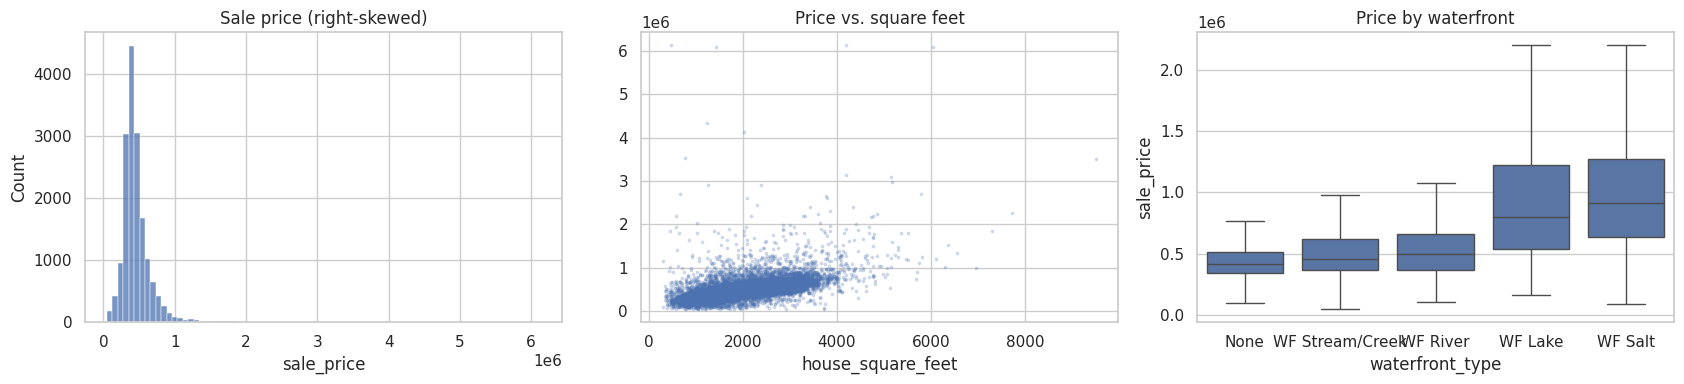

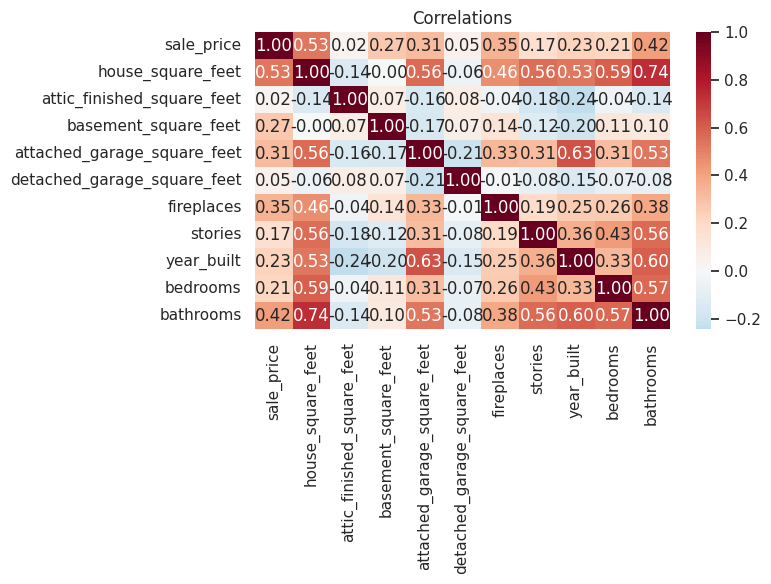

(16658, 31)
train: (13326, 30)  test: (3332, 30)


In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

URL = "https://raw.githubusercontent.com/elijahschoeniger-cpu/L02-hedonic-pricing/main/data/pierce_county_house_sales.csv"
df_raw = pd.read_csv(URL)

df = df_raw.drop_duplicates().copy()

# Drop impossible / non-market records
df = df[(df["sale_price"] >= 50_000)          # $2k-$50k sales = non-arm's-length transfers
        & (df["house_square_feet"] >= 300)     # 1 sq ft houses etc.
        & (df["stories"] > 0)
        & (df["bedrooms"] <= 12)]              # one 25-bedroom record

# NaN here not missing
df["waterfront_type"] = df["waterfront_type"].fillna("None")
df["view_quality"] = df["view_quality"].fillna("No View")

# Only ~10 rows missing these; drop them
df = df.dropna(subset=["hvac_description", "exterior", "interior", "roof_cover"])

# Fix inconsistent labels
df["hvac_description"] = df["hvac_description"].replace(
    {"Floor Wall Furnace": "Floor/Wall Furnace", "Electric": "Electric Baseboard"})

df = df[df["bathrooms"] > 0]

df["sale_date"] = pd.to_datetime(df["sale_date"])
df = df.reset_index(drop=True)
print(f"{len(df_raw)} -> {len(df)} rows; missing values left: {df.isna().sum().sum()}")

num_cols = ["house_square_feet", "attic_finished_square_feet", "basement_square_feet",
            "attached_garage_square_feet", "detached_garage_square_feet",
            "fireplaces", "stories", "year_built", "bedrooms", "bathrooms"]

print(df.describe().T)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(df["sale_price"], bins=80, ax=ax[0]).set_title("Sale price (right-skewed)")
ax[1].scatter(df["house_square_feet"], df["sale_price"], s=3, alpha=0.2)
ax[1].set(title="Price vs. square feet", xlabel="house_square_feet")
order = df.groupby("waterfront_type")["sale_price"].median().sort_values().index
sns.boxplot(data=df, x="waterfront_type", y="sale_price", order=order, showfliers=False, ax=ax[2])
ax[2].set_title("Price by waterfront")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df[["sale_price"] + num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlations"); plt.tight_layout(); plt.show()

#Price is heavily right skewed, square footage footage is strongest r=0.53, followed by bathrooms.


#Q2
X = df.copy()
X["sale_month"] = X["sale_date"].dt.month

# Ordered view grades -> 0..8
view_order = ["No View", "View Lim -", "View Lim", "View Lim +", "View Avg",
              "View Avg +", "View Good", "View Good +", "View V-Good"]
X["view_score"] = X["view_quality"].map({v: i for i, v in enumerate(view_order)})

# Near-constant columns -> one binary flag each
X["interior_drywall"] = (X["interior"] == "Drywall").astype(int)
X["sewer_installed"] = (X["utility_sewer"] == "SEWER/SEPTIC INSTALLED").astype(int)

# Group rare levels
X["exterior"] = X["exterior"].replace({"Masonry Common Brick": "Masonry", "Masonry Concrete Block": "Masonry"})
X["exterior"] = X["exterior"].where(X["exterior"].isin(["Frame Siding", "Frame Vinyl", "Masonry", "Frame Stucco"]), "Other")
X["hvac_description"] = X["hvac_description"].where(
    X["hvac_description"].isin(["Forced Air", "Electric Baseboard", "Heat Pump", "Warm and Cool Air Zone"]), "Other")
X["roof_cover"] = X["roof_cover"].replace({"Formed Seam Metal": "Metal", "Preformed Metal": "Metal"})

X = X.drop(columns=["sale_date", "view_quality", "interior", "utility_sewer"])

# One-hot encode with most common level as the dropped baseline
for c, base in {"exterior": "Frame Siding", "hvac_description": "Forced Air",
                "roof_cover": "Composition Shingle", "waterfront_type": "None"}.items():
    X[c] = pd.Categorical(X[c], categories=[base] + sorted(set(X[c]) - {base}))
X = pd.get_dummies(X, columns=["exterior", "hvac_description", "roof_cover", "waterfront_type"],
                   drop_first=True, dtype=int)
X.columns = X.columns.str.replace(r"[ /]+", "_", regex=True)

print(X.shape)
X.head()

#sale_date goes to sale_month, view_quality


#Q3
y = X.pop("sale_price")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("train:", X_train.shape, " test:", X_test.shape)





## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [9]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]